# 02 – Risco geopolítico ponderado e baselines

Resultados dos scripts `src/08_gpr_ponderado.py` e `src/09_baselines.py` (rode-os antes deste notebook).

1. Índice de risco geopolítico (GPR) ponderado pela origem das importações de cada fertilizante
2. Baselines de previsão (ingênuo, ingênuo sazonal, ARIMA) com validação por origem móvel, h = 1, 2, 3
3. Recortes: choques (2021–23, Ormuz 2026), fora dos choques, janela de compra e ponderação pelo volume

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TAB, FIG = ROOT / "reports/tables", ROOT / "reports/figures"
pd.set_option("display.max_rows", 100)

## 1. GPR ponderado pela origem

$GPR^{pond}_{p,t} = \sum_c w_{p,c,a(t)-1} \cdot GPRC_{c,t} / \overline{GPRC_c}^{1985-2019} \times 100$

Os pesos são as participações de cada país no volume importado do produto **no ano anterior** (sem informação futura).
Países sem índice próprio (Belarus, Catar, Omã, Marrocos, Argélia…) usam um proxy regional; os demais (ex.: Nigéria) usam o GPR global.

,produto,ano,country,peso,tipo
0,KCl,2025,Rússia,45.3,direto
1,KCl,2025,Canadá,37.7,direto
2,KCl,2025,Israel,8.0,direto
3,KCl,2025,Alemanha,3.9,direto
4,KCl,2025,Turcomenistão,2.5,proxy
5,KCl,2025,Jordânia,1.6,proxy
6,MAP,2025,Rússia,45.9,direto
7,MAP,2025,Arábia Saudita,24.8,direto
8,MAP,2025,Marrocos,22.6,proxy
9,MAP,2025,China,3.4,direto


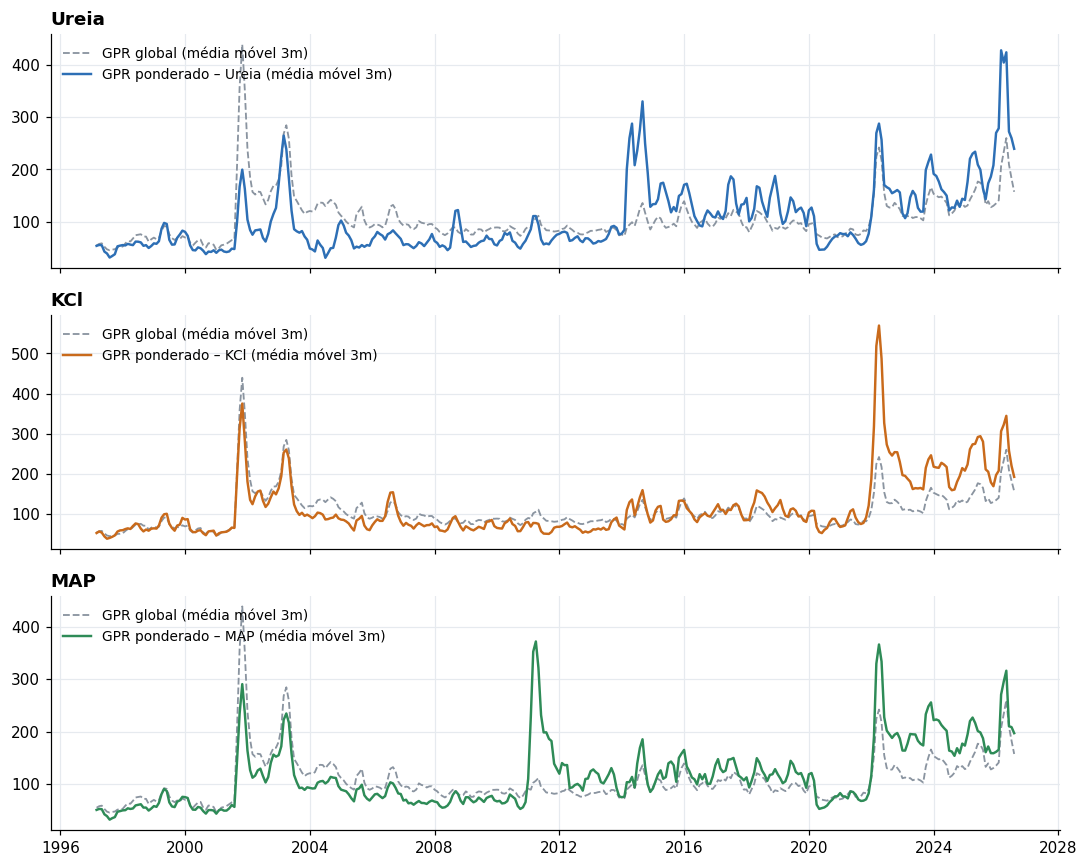

In [2]:
display(pd.read_csv(TAB / "02_gpr_origens_2025.csv"))
display(Image(FIG / "02_gpr_ponderado.png"))

**Conteúdo preditivo (exploratório):** correlação entre a variação do índice nos últimos 3 meses e a variação futura do preço (log) em h meses.

In [3]:
pd.read_csv(TAB / "02_gpr_correlacao_preditiva.csv", index_col=[0, 1])

gpr_global  gpr_ponderado
produto h                           
KCl     1       0.054          0.076
        2       0.086          0.114
        3       0.083          0.123
MAP     1       0.082          0.089
        2       0.081          0.063
        3       0.069          0.051
Ureia   1       0.075          0.099
        2       0.107          0.126
        3       0.043          0.091

## 2. Baselines – RMSE (US$/t) e razão ARIMA / ingênuo

In [4]:
rel = pd.read_csv(TAB / "03_baselines_rmse_relativo.csv")
rel.pivot_table(index=["produto", "recorte"], columns="h", values="ARIMA / ingênuo (RMSE)").round(3)

h                                  1      2      3
produto recorte                                   
KCl     Choque 2021–23         0.797  0.820  0.904
        Fora dos choques       0.839  0.799  0.807
        Janela de compra       0.856  0.879  0.873
        Ormuz 2026             0.932  0.912  0.922
        Ponderado pelo volume  0.804  0.826  0.896
        Todos (2010–2026)      0.805  0.816  0.889
MAP     Choque 2021–23         0.832  0.902  0.937
        Fora dos choques       0.955  0.960  0.971
        Janela de compra       0.842  0.940  0.970
        Ormuz 2026             0.794  0.883  0.934
        Ponderado pelo volume  0.871  0.920  0.950
        Todos (2010–2026)      0.872  0.917  0.947
Ureia   Choque 2021–23         0.973  0.954  0.935
        Fora dos choques       0.953  0.964  0.995
        Janela de compra       0.935  0.935  0.974
        Ormuz 2026             0.906  0.939  1.027
        Ponderado pelo volume  0.953  0.956  0.974
        Todos (2010–2026)      0.958  0.955  0.971

In [5]:
rel[rel["recorte"] == "Todos (2010–2026)"].drop(columns="recorte")

,produto,h,n,ingenuo RMSE,ingenuo_sazonal RMSE,arima RMSE,ARIMA / ingênuo (RMSE)
0,KCl,1,197,23.6,179.4,19.0,0.805
6,KCl,2,197,42.5,176.9,34.7,0.816
12,KCl,3,197,60.3,174.1,53.6,0.889
18,MAP,1,197,31.2,183.4,27.2,0.872
24,MAP,2,197,54.3,172.0,49.8,0.917
30,MAP,3,197,73.1,170.4,69.2,0.947
36,Ureia,1,197,26.3,130.1,25.2,0.958
42,Ureia,2,197,44.9,130.1,42.9,0.955
48,Ureia,3,197,59.4,130.1,57.7,0.971


### Teste de Diebold–Mariano (H1: ARIMA tem erro quadrático menor que o ingênuo)

In [6]:
pd.read_csv(TAB / "03_teste_dm.csv")

,produto,h,DM (ingênuo vs ARIMA),p-valor (ARIMA melhor)
0,KCl,1,2.75,0.003
1,KCl,2,1.74,0.042
2,KCl,3,0.97,0.168
3,MAP,1,3.13,0.001
4,MAP,2,2.28,0.012
5,MAP,3,2.13,0.017
6,Ureia,1,1.43,0.076
7,Ureia,2,1.97,0.025
8,Ureia,3,1.18,0.120


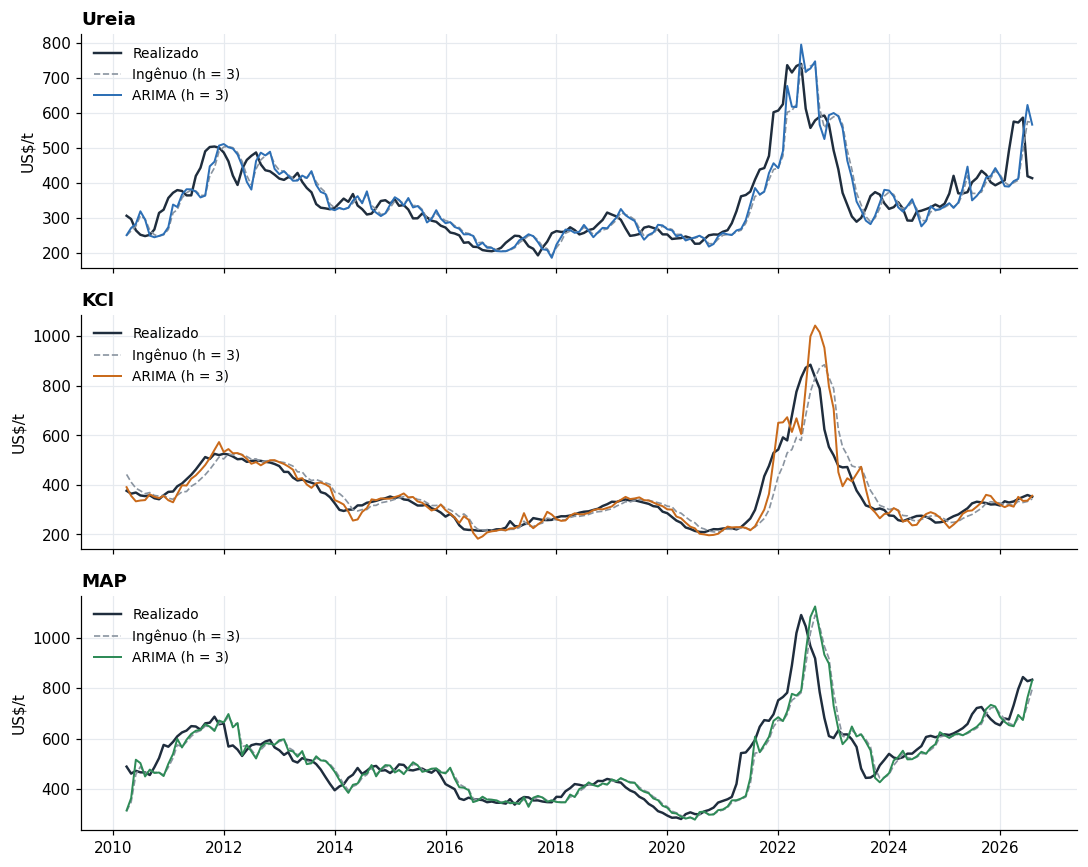

In [7]:
display(Image(FIG / "03_baselines_h3.png"))

## 3. Leitura

**GPR ponderado**
- As origens mudaram muito: em 2025 o KCl vem da Rússia (45%) e do Canadá (38%), sem Belarus; a ureia vem da Nigéria (23%),
  do Golfo (Omã e Catar, 28%) e da Rússia (17%); o MAP, da Rússia (46%), Arábia Saudita (25%) e Marrocos (23%).
- Cobertura com índice próprio: 83% (KCl), 75% (MAP) e 65% (ureia); o resto usa proxy regional ou o GPR global.
- O índice ponderado antecipa um pouco melhor que o global para ureia e KCl, mas as correlações são baixas (≈ 0,1).
  **O risco geopolítico sozinho é um preditor fraco**; o preço internacional defasado (correlação 0,4–0,6) deve carregar mais sinal.
  O GPR tende a ser mais útil como variável de regime (choque) do que como preditor linear.

**Baselines**
- O ARIMA supera o ingênuo em todos os produtos e horizontes no período completo (RMSE 3% a 20% menor), com ganho
  significativo (DM, 5%) para KCl (h = 1, 2), MAP (h = 1, 2, 3) e ureia (h = 2).
- O **ingênuo sazonal é muito pior** (RMSE 2 a 8 vezes maior): confirma que o preço não é sazonal.
- Nos choques de 2021–23 o erro de todos os modelos fica 3 a 5 vezes maior que fora deles; no choque de Ormuz, para ureia em h = 3, o ARIMA não supera o ingênuo.
- **Régua para os próximos modelos:** o ARIMA é o baseline a bater. Os modelos com preço internacional, câmbio e GPR (SARIMAX,
  LASSO, gradient boosting, LSTM) precisam reduzir o RMSE do ARIMA, sobretudo nos choques e na janela de compra.